# EN3150 Assignment 03: MobileNetV2 fine-tuning (Task 5)

**MobileNetV2** (Sandler et al., 2018) is built from *inverted residual* blocks: a pointwise $1 \times 1$ expansion, a depthwise $3 \times 3$ convolution and a linear $1 \times 1$ projection, with ReLU6 activations. ReLU6 is a clipped ReLU (`min(max(0, x), 6)`), so like Models A and B it needs no exponentials and its bounded range suits 8-bit quantisation.

The ImageNet-pretrained model is fine-tuned on GTSRB with **exactly the same recipe as `EfficientNetB0`**
(`SOTA/EfficientNetB0/src/EfficientNetB0_Retrain.ipynb`), and with the same data pipeline as Models A and B, so all four models can be compared
directly.

| Setting | Value |
|---|---|
| Data | `splits/*.csv` (70/15/15), $64 \times 64$ input, `Common/dataset.py` augmentation |
| Normalisation | ImageNet mean / std (the statistics the pretrained weights expect) |
| Batch size / loss | 32 / cross-entropy |
| Stage 1: head warm-up | 3 epochs, backbone frozen, new 43-class head trained with Adam (lr = 1e-3) |
| Stage 2: full fine-tuning | 17 epochs, all layers trainable, Adam (lr = 1e-4) with cosine decay |
| Weights kept | Epoch with the lowest validation loss (same rule as `Common/training.py`) |

The input stays at $64 \times 64$ (no upsampling to 224), keeping the edge-sensor constraint of the assignment.
The head is trained alone first so its random initial gradients do not damage the pretrained features; the whole
network is then unfrozen, because $64 \times 64$ traffic signs are very different from ImageNet photographs.

In [1]:
import copy
import json
import random
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import transforms
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

from sklearn.metrics import confusion_matrix, classification_report

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: NVIDIA GeForce GTX 1660 Ti


In [4]:
def find_project_root():
    current = Path.cwd().resolve()

    while current != current.parent:
        if (current / ".git").exists():
            return current

        current = current.parent

    raise FileNotFoundError("Could not find project root.")


PROJECT_ROOT = find_project_root()

DATA_ROOT = PROJECT_ROOT / "data" / "gtsrb"
SPLIT_DIR = PROJECT_ROOT / "splits"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "MobileNetV2"
METRICS_DIR = RESULTS_DIR / "MobileNetV2"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: E:\UOM resourses\Sem 5\Pattern Recognition\Assignment 3


In [5]:
from Common.dataset import create_dataloaders
from Common.training import train_one_epoch, evaluate_epoch
from Common.evaluation import (
    get_predictions,
    calculate_metrics,
    plot_training_curves,
    plot_confusion_matrix,
    print_classification_report,
    total_parameters,
    trainable_parameters,
    estimated_fp32_size_kb,
    save_model_and_get_size,
    measure_inference_time
)
from Common.complexity import count_macs

## 1. Data preparation

Same split files and the same augmentation as `Common/dataset.py`; only the final normalisation changes to the
ImageNet statistics.

In [6]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

imagenet_train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomRotation(degrees=8),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

imagenet_eval_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

In [7]:
train_df = pd.read_csv(SPLIT_DIR / "train_split.csv")
val_df = pd.read_csv(SPLIT_DIR / "val_split.csv")
test_df = pd.read_csv(SPLIT_DIR / "test_split.csv")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

train_loader, val_loader, test_loader = create_dataloaders(
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    data_root=DATA_ROOT,
    batch_size=32,
    num_workers=0,
    train_transform_override=imagenet_train_transform,
    eval_transform_override=imagenet_eval_transform,
    seed=SEED
)

images, labels = next(iter(train_loader))
print(f"Image batch shape: {tuple(images.shape)}")
assert images.shape[1:] == (3, 64, 64)

Train: 18648
Validation: 3996
Test: 3996


Image batch shape: (32, 3, 64, 64)


## 2. Pretrained MobileNetV2 with a new 43-class head

The ImageNet classifier `Dropout(0.2) -> Linear(1280, 1000)` is kept except for the final linear layer, which is
replaced by `Linear(1280, 43)`. Pretrained weights are cached in `checkpoints/torch_hub/` (gitignored).

In [8]:
torch.hub.set_dir(str(CHECKPOINT_DIR / "torch_hub"))

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

model = mobilenet_v2(weights=MobileNet_V2_Weights.IMAGENET1K_V1)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 43)
model = model.to(device)

parameters_total = total_parameters(model)
parameters_backbone = sum(p.numel() for p in model.features.parameters())
parameters_head = sum(p.numel() for p in model.classifier.parameters())

print(f"Total parameters:      {parameters_total:,}")
print(f"  Backbone (features): {parameters_backbone:,}")
print(f"  New head (1280->43): {parameters_head:,}")
assert parameters_head == 1280 * 43 + 43

macs = count_macs(model)
print(f"MACs per 64x64 image:  {macs:,}")

model.eval()
with torch.inference_mode():
    logits = model(images.to(device))
assert logits.shape == (images.shape[0], 43)
assert torch.isfinite(logits).all()
print(f"Smoke check passed: {tuple(images.shape)} -> {tuple(logits.shape)}")

Total parameters:      2,278,955
  Backbone (features): 2,223,872
  New head (1280->43): 55,083


MACs per 64x64 image:  24,503,552


Smoke check passed: (32, 3, 64, 64) -> (32, 43)


## 3. Two-stage fine-tuning

The loop uses `train_one_epoch` and `evaluate_epoch` from `Common/training.py`, so each epoch is trained and timed
exactly like Models A and B. It is written out here because stage 2 needs a learning-rate scheduler, which
`train_model` does not support. The weights with the lowest validation loss across both stages are kept.

In [9]:
criterion = nn.CrossEntropyLoss()

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "epoch_time": [],
    "stage": []
}

best_val_loss = float("inf")
best_weights = copy.deepcopy(model.state_dict())


def run_stage(stage, epochs, optimizer, scheduler=None):
    global best_val_loss, best_weights

    print(f"{stage}: {trainable_parameters(model):,} trainable parameters")

    for epoch in range(epochs):
        start_time = time.perf_counter()

        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_epoch(model, val_loader, criterion, device)

        if device.type == "cuda":
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - start_time

        if scheduler is not None:
            scheduler.step()

        for key, value in [
            ("train_loss", train_loss),
            ("train_accuracy", train_acc),
            ("val_loss", val_loss),
            ("val_accuracy", val_acc),
            ("epoch_time", elapsed),
            ("stage", stage)
        ]:
            history[key].append(value)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())

        print(
            f"[{stage}] Epoch {len(history['train_loss']):02d} | "
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Time: {elapsed:.2f}s"
        )

In [10]:
HEAD_EPOCHS = 3
FINE_TUNE_EPOCHS = 17

# Stage 1: backbone frozen, only the new head is trained
for parameter in model.features.parameters():
    parameter.requires_grad = False

head_optimizer = optim.Adam(
    [parameter for parameter in model.parameters() if parameter.requires_grad],
    lr=1e-3
)
run_stage("head", HEAD_EPOCHS, head_optimizer)

# Stage 2: every layer trainable, smaller learning rate with cosine decay
for parameter in model.parameters():
    parameter.requires_grad = True

fine_tune_optimizer = optim.Adam(model.parameters(), lr=1e-4)
fine_tune_scheduler = optim.lr_scheduler.CosineAnnealingLR(fine_tune_optimizer, T_max=FINE_TUNE_EPOCHS)
run_stage("full", FINE_TUNE_EPOCHS, fine_tune_optimizer, fine_tune_scheduler)

model.load_state_dict(best_weights)
best_epoch = int(np.argmin(history["val_loss"])) + 1
print(f"Restored weights from epoch {best_epoch} (validation loss {best_val_loss:.4f})")

METRICS_DIR.mkdir(parents=True, exist_ok=True)
with (METRICS_DIR / "mobilenetv2_history.json").open("w", encoding="utf-8") as history_file:
    json.dump(history, history_file, indent=2)

head: 55,083 trainable parameters


[head] Epoch 01 | Train Loss: 2.0073 | Train Acc: 0.4168 | Val Loss: 1.6855 | Val Acc: 0.4975 | Time: 151.52s


[head] Epoch 02 | Train Loss: 1.6034 | Train Acc: 0.5073 | Val Loss: 1.4495 | Val Acc: 0.5641 | Time: 40.52s


[head] Epoch 03 | Train Loss: 1.5081 | Train Acc: 0.5346 | Val Loss: 1.3616 | Val Acc: 0.5793 | Time: 40.56s
full: 2,278,955 trainable parameters


[full] Epoch 04 | Train Loss: 0.6440 | Train Acc: 0.7850 | Val Loss: 0.1994 | Val Acc: 0.9327 | Time: 53.57s


...

[full] Epoch 16 | Train Loss: 0.0082 | Train Acc: 0.9978 | Val Loss: 0.0016 | Val Acc: 0.9992 | Time: 55.97s


[full] Epoch 17 | Train Loss: 0.0049 | Train Acc: 0.9988 | Val Loss: 0.0024 | Val Acc: 0.9992 | Time: 56.16s


[full] Epoch 18 | Train Loss: 0.0044 | Train Acc: 0.9986 | Val Loss: 0.0018 | Val Acc: 0.9995 | Time: 56.19s


[full] Epoch 19 | Train Loss: 0.0046 | Train Acc: 0.9986 | Val Loss: 0.0017 | Val Acc: 0.9995 | Time: 56.21s


[full] Epoch 20 | Train Loss: 0.0042 | Train Acc: 0.9987 | Val Loss: 0.0012 | Val Acc: 0.9997 | Time: 56.28s
Restored weights from epoch 20 (validation loss 0.0012)


## 4. Evaluation

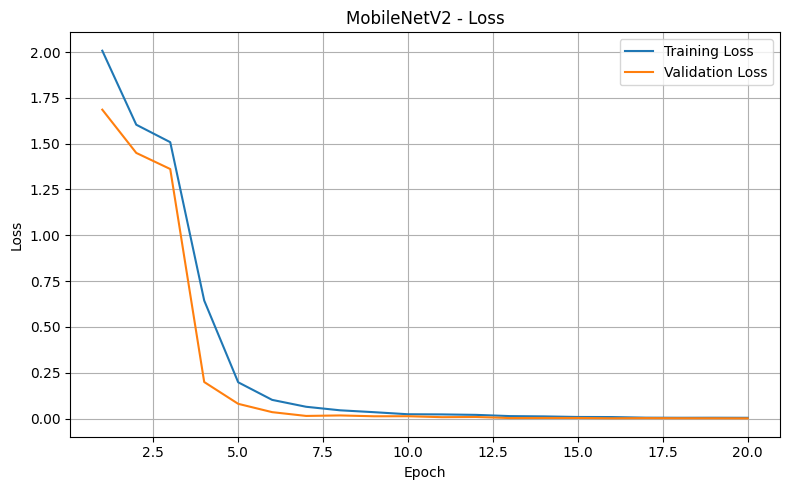

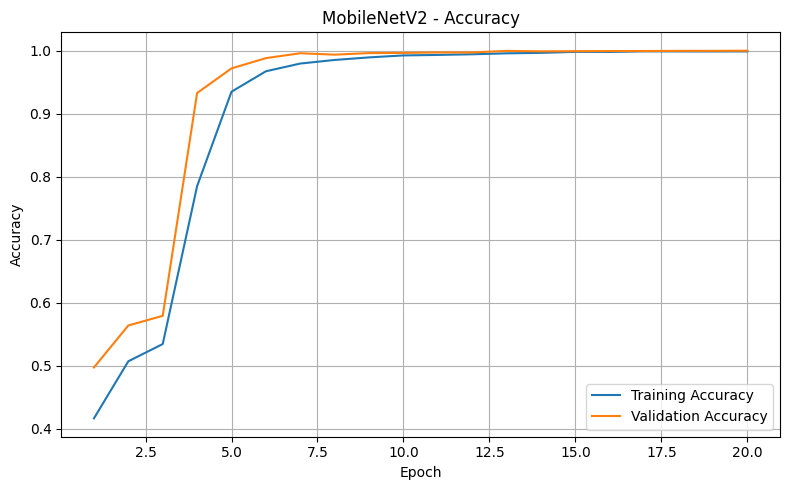

In [11]:
plot_training_curves(
    history=history,
    model_name="MobileNetV2",
    save_dir=FIGURES_DIR
)

{'Test Accuracy': 1.0, 'Macro Precision': 1.0, 'Macro Recall': 1.0}


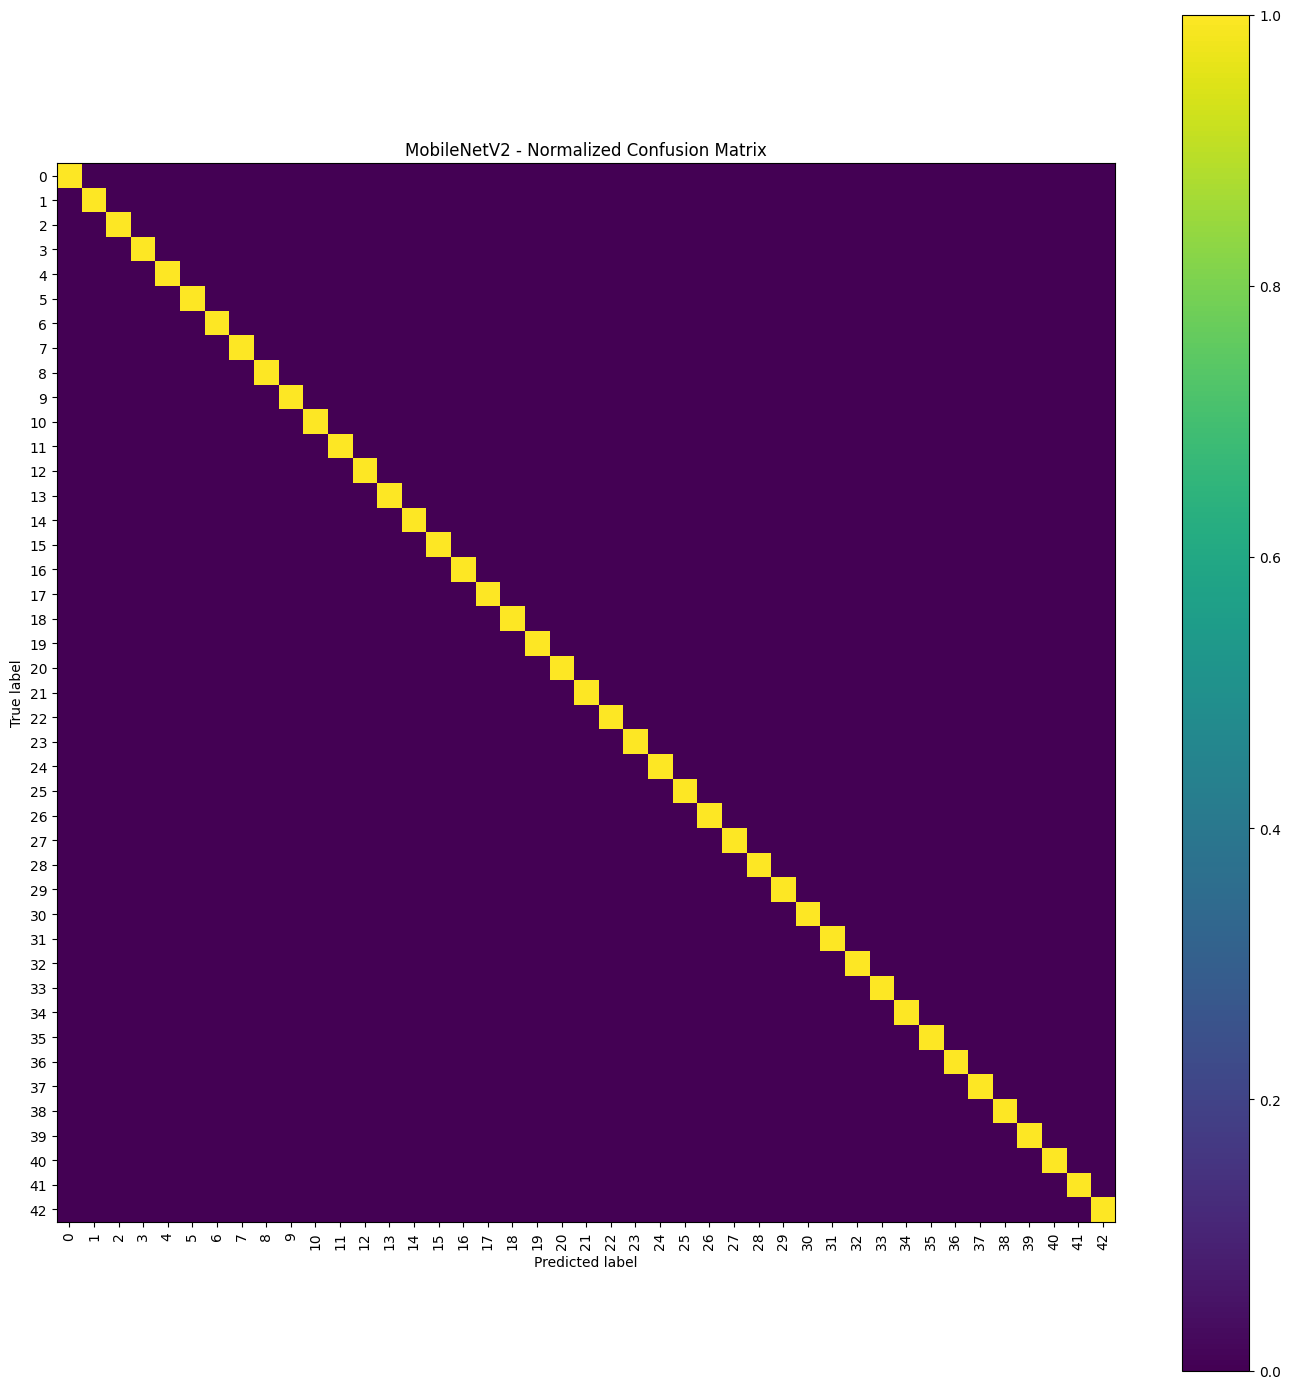

In [12]:
y_true, y_pred = get_predictions(model, test_loader, device)

metrics = calculate_metrics(y_true, y_pred)

print(metrics)

plot_confusion_matrix(
    y_true,
    y_pred,
    model_name="MobileNetV2",
    save_dir=FIGURES_DIR
)

In [13]:
report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
print_classification_report(y_true, y_pred)

with (METRICS_DIR / "mobilenetv2_classification_report.json").open("w", encoding="utf-8") as report_file:
    json.dump(report, report_file, indent=2)
np.savetxt(
    METRICS_DIR / "mobilenetv2_confusion_matrix.csv",
    confusion_matrix(y_true, y_pred, labels=list(range(43))),
    fmt="%d",
    delimiter=","
)

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        19
           1     1.0000    1.0000    1.0000       223
           2     1.0000    1.0000    1.0000       233
           3     1.0000    1.0000    1.0000       148
           4     1.0000    1.0000    1.0000       221
           5     1.0000    1.0000    1.0000       209
           6     1.0000    1.0000    1.0000        47
           7     1.0000    1.0000    1.0000       155
           8     1.0000    1.0000    1.0000       144
           9     1.0000    1.0000    1.0000       155
          10     1.0000    1.0000    1.0000       197
          11     1.0000    1.0000    1.0000       139
          12     1.0000    1.0000    1.0000       213
          13     1.0000    1.0000    1.0000       213
          14     1.0000    1.0000    1.0000        78
          15     1.0000    1.0000    1.0000        82
          16     1.0000    1.0000    1.0000        34
          17     1.0000    

## 5. Edge-deployment measurements

In [14]:
average_epoch_time = float(np.mean(history["epoch_time"]))

estimated_size_kb = estimated_fp32_size_kb(model)
actual_size_kb = save_model_and_get_size(model, CHECKPOINT_DIR / "mobilenetv2_final.pth")

inference_time = measure_inference_time(model, test_loader, device)

print("Parameters:", parameters_total)
print("MACs per image:", macs)
print(f"Estimated FP32 size: {estimated_size_kb / 1024:.2f} MB")
print(f"Size on disk:        {actual_size_kb / 1024:.2f} MB")
print(f"Average epoch time:  {average_epoch_time:.2f} s")
print(f"Inference time:      {inference_time:.3f} ms/image")

Parameters: 2278955
MACs per image: 24503552
Estimated FP32 size: 8.69 MB
Size on disk:        8.93 MB
Average epoch time:  59.17 s
Inference time:      0.598 ms/image


In [15]:
results = {
    "Model": "MobileNetV2",
    "Parameters": parameters_total,
    "MACs per Image": macs,
    "Estimated FP32 Size (MB)": estimated_size_kb / 1024,
    "Model Size (MB)": actual_size_kb / 1024,
    "Average Epoch Time (s)": average_epoch_time,
    "Inference Time (ms/image)": inference_time,
    "Test Accuracy": metrics["Test Accuracy"],
    "Macro Precision": metrics["Macro Precision"],
    "Macro Recall": metrics["Macro Recall"]
}

results_df = pd.DataFrame([results])

results_df.to_csv(METRICS_DIR / "mobilenetv2_metrics.csv", index=False)

results_df

,Model,Parameters,MACs per Image,Estimated FP32 Size (MB),Model Size (MB),Average Epoch Time (s),Inference Time (ms/image),Test Accuracy,Macro Precision,Macro Recall
0,MobileNetV2,2278955,24503552,8.693523,8.929881,59.172997,0.598415,1.0,1.0,1.0
